# Sistemas de ecuaciones lineales

Resolución de los once enunciados principales y los cinco ejercicios opcionales mediante métodos directos e iterativos: factorización $LU$, eliminación gaussiana, relajación (SOR) y los esquemas de Jacobi y Gauss–Seidel. Para cada sistema se evalúa el criterio de convergencia, se documenta el desarrollo de las iteraciones y se cuantifica el error cuando se dispone de la solución exacta.

| Sección | Contenido |
|---|---|
| 1 | Formulación: descomposición de la matriz, métodos iterativos, criterios de convergencia, $LU$ y análisis espectral |
| 2 | Enunciados 1 a 11 |
| 3 | Ejercicios opcionales 1 a 5 |
| 4 | Cuadro resumen de convergencia |

Se emplea la convención de descomposición

$$A = D - E - F,$$

donde $D$ es la matriz diagonal, $E$ la estrictamente triangular inferior y $F$ la estrictamente triangular superior. Con esta notación, las matrices de iteración de Jacobi y Gauss–Seidel se expresan en forma unificada, en concordancia con las definiciones adoptadas en los enunciados.

In [1]:
%matplotlib inline

import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import display

pd.set_option("display.max_columns", 25)

plt.rcParams.update({
    "figure.figsize": (7.5, 3.4),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.30,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.fontsize": 8,
})

np.set_printoptions(precision=6, suppress=True)
print("Entorno listo: numpy", np.__version__, "| pandas", pd.__version__, "| sympy", sp.__version__)

Entorno listo: numpy 2.5.4 | pandas 3.1.0 | sympy 1.14.0


## 1. Formulación

### 1.1 Descomposición de la matriz

Un sistema $A\vec{x} = \vec{b}$ con $A \in \mathbb{R}^{n \times n}$ admite la descomposición

$$A = D - E - F,$$

con

$$D = \operatorname{diag}(a_{11}, \dots, a_{nn}), \qquad
E = -\operatorname{tril}(A, -1), \qquad
F = -\operatorname{triu}(A, 1).$$

Los métodos iterativos parten de una aproximación inicial $\vec{x}^{(0)}$ y generan una sucesión $\{\vec{x}^{(k)}\}$ que, bajo condiciones apropiadas, converge a la solución $\vec{x}^*$.

### 1.2 Método de Jacobi

Reordenando la ecuación $A\vec{x} = \vec{b}$ de modo que cada incógnita se expresa en función de las demás, la iteración es

$$D\,\vec{x}^{(k+1)} = (E + F)\,\vec{x}^{(k)} + \vec{b},$$

de donde

$$\vec{x}^{(k+1)} = J\,\vec{x}^{(k)} + D^{-1}\vec{b}, \qquad J = I - D^{-1}A = D^{-1}(E+F).$$

En forma componente:

$$x_i^{(k+1)} = \frac{1}{a_{ii}}\left(b_i - \sum_{j \neq i} a_{ij}\,x_j^{(k)}\right).$$

### 1.3 Método de Gauss–Seidel

Sustituye inmediatamente los componentes ya actualizados en el cálculo de los siguientes:

$$\vec{x}^{(k+1)} = G\,\vec{x}^{(k)} + (D - E)^{-1}\vec{b}, \qquad G = (D - E)^{-1}F,$$

en forma componente:

$$x_i^{(k+1)} = \frac{1}{a_{ii}}\left(b_i - \sum_{j < i} a_{ij}\,x_j^{(k+1)} - \sum_{j > i} a_{ij}\,x_j^{(k)}\right).$$

Al aprovechar los valores ya calculados del mismo paso, Gauss–Seidel suele converger más rápidamente que Jacobi; sin embargo, la relación de convergencia entre ambos no está garantizada en general.

### 1.4 Método de relajación (SOR)

El método de sobre-relajación sucesiva introduce un parámetro $0 < \omega < 2$ que interpola entre el valor anterior y el que propondría Gauss–Seidel:

$$\vec{x}^{(k+1)} = (1 - \omega)\,\vec{x}^{(k)} + \omega\,G\,\vec{x}^{(k)} + \omega\,(D - E)^{-1}\vec{b},$$

con matriz de iteración

$$T_{\text{SOR}} = (D - \omega E)^{-1}\big[(1 - \omega)D + \omega F\big].$$

En forma componente:

$$x_i^{(k+1)} = (1-\omega)\,x_i^{(k)} + \frac{\omega}{a_{ii}}\left(b_i - \sum_{j < i} a_{ij}\,x_j^{(k+1)} - \sum_{j > i} a_{ij}\,x_j^{(k)}\right).$$

Para $\omega = 1$ el método coincide con Gauss–Seidel. El parámetro óptimo $\omega_{\text{ópt}}$ minimiza el radio espectral $\rho(T_{\text{SOR}})$. Para matrices simétricas definidas positivas de ordenación consistente se tiene la fórmula clásica

$$\omega_{\text{ópt}} = \frac{2}{1 + \sqrt{1 - \rho(J)^2}}.$$

Cuando la matriz carece de la Propiedad A, dicha expresión constituye una estimación heurística y el valor óptimo debe determinarse por minimización directa de $\rho(T_{\text{SOR}})$.

### 1.5 Criterios de convergencia

**Condición suficiente - dominancia diagonal.** El método iterativo converge si

$$|a_{ii}| > \sum_{j \neq i} |a_{ij}| \quad \text{para todo } i,$$

esto es, si $A$ es diagonalmente dominante por filas. En tal caso la norma infinito de ambas matrices de iteración es estrictamente menor que $1$.

**Criterio necesario y suficiente - radio espectral.** El método iterativo converge si y solo si

$$\rho(T) < 1, \qquad \rho(T) = \max_i |\lambda_i(T)|.$$

El radio espectral gobierna la tasa asintótica de convergencia: $\|\vec{x}^{(k)} - \vec{x}^*\| \approx C\,\rho(T)^k$. A diferencia de la dominancia diagonal, el criterio del radio espectral es exacto, pero exige calcular los autovalores de $T$.

### 1.6 Factorización $LU$

Se busca $A = LU$ con $L$ triangular inferior de unos en la diagonal (factorización de Doolittle) y $U$ triangular superior. Resuelto el sistema en dos etapas:

$$L\vec{y} = \vec{b} \quad (\text{sustitución hacia adelante}), \qquad U\vec{x} = \vec{y} \quad (\text{sustitución hacia atrás}).$$

Al ser $L$ de unos en la diagonal, el determinante se obtiene como el producto de los elementos diagonales de $U$:

$$\det(A) = \prod_{i=1}^{n} u_{ii}.$$

### 1.7 Análisis espectral

Los autovalores $\lambda$ de una matriz $T$ resuelven el polinomio característico

$$p(\lambda) = \det(T - \lambda I) = 0,$$

y los autovectores $\vec{v}$ asociados satisfacen $(T - \lambda I)\vec{v} = \vec{0}$. El radio espectral de la matriz de iteración determina la convergencia del método correspondiente.

In [2]:
def tabla(df, dec=6):
    fmt = lambda v: f"{v:.{dec}f}"
    with pd.option_context("display.float_format", fmt):
        display(df.reset_index(drop=True))


def descomponer(A):
    # Devuelve (D, E, F) con A = D - E - F
    A = np.array(A, dtype=float)
    D = np.diag(np.diag(A))
    E = -np.tril(A, -1)
    F = -np.triu(A, 1)
    return D, E, F


def matriz_jacobi(A):
    # J = I - D^{-1} A
    A = np.array(A, dtype=float)
    D = np.diag(np.diag(A))
    return np.eye(A.shape[0]) - np.linalg.solve(D, A)


def matriz_gauss_seidel(A):
    # G = (D - E)^{-1} F
    A = np.array(A, dtype=float)
    D, E, F = descomponer(A)
    return np.linalg.solve(D - E, F)


def matriz_sor(A, w):
    # T_SOR = (D - w E)^{-1} [(1 - w) D + w F]
    A = np.array(A, dtype=float)
    D, E, F = descomponer(A)
    return np.linalg.solve(D - w * E, (1 - w) * D + w * F)


def radio_espectral(T):
    return float(np.max(np.abs(np.linalg.eigvals(T))))


def dominancia_diagonal(A):
    # Devuelve (tabla de cotas, es_diagonalmente_dominante)
    A = np.array(A, dtype=float)
    d = np.abs(np.diag(A))
    off = np.sum(np.abs(A), axis=1) - d
    filas = [[i + 1, A[i, i], d[i], off[i], d[i] - off[i], d[i] > off[i]]
             for i in range(A.shape[0])]
    df = pd.DataFrame(filas, columns=["fila i", "a_ii", "|a_ii|", "sum_{j!=i}|a_ij|",
                                      "margen", "dominante"])
    return df, bool(np.all(d > off))


def omega_optimo(A, w_max=1.95, pasos=1901):
    # Determina w que minimiza rho(T_SOR) por barrido sobre [1, w_max).
    mejor_w, mejor_r = 1.0, radio_espectral(matriz_sor(A, 1.0))
    for w in np.linspace(1.0, w_max, pasos):
        r = radio_espectral(matriz_sor(A, w))
        if r < mejor_r:
            mejor_r, mejor_w = r, w
    return mejor_w, mejor_r


def jacobi(A, b, x0, n):
    # Iteracion de Jacobi. Devuelve (tabla, aproximacion final).
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    D = np.diag(np.diag(A))
    Db = np.linalg.solve(D, b)
    J = matriz_jacobi(A)
    x = np.array(x0, dtype=float)
    filas = []
    for k in range(1, n + 1):
        x_old = x.copy()
        x = J @ x_old + Db
        filas.append([k] + list(x_old) + list(x) + [np.max(np.abs(x - x_old))])
    cols = ["k"] + [f"x{i}^(k-1)" for i in range(1, len(b) + 1)] + \
           [f"x{i}^(k)" for i in range(1, len(b) + 1)] + ["||dx||_inf"]
    return pd.DataFrame(filas, columns=cols), x


def gauss_seidel(A, b, x0, n):
    # Iteracion de Gauss-Seidel. Devuelve (tabla, aproximacion final).
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    D, E, F = descomponer(A)
    G = matriz_gauss_seidel(A)
    rhs = np.linalg.solve(D - E, b)
    x = np.array(x0, dtype=float)
    filas = []
    for k in range(1, n + 1):
        x_old = x.copy()
        x = G @ x_old + rhs
        filas.append([k] + list(x_old) + list(x) + [np.max(np.abs(x - x_old))])
    cols = ["k"] + [f"x{i}^(k-1)" for i in range(1, len(b) + 1)] + \
           [f"x{i}^(k)" for i in range(1, len(b) + 1)] + ["||dx||_inf"]
    return pd.DataFrame(filas, columns=cols), x


def sor(A, b, x0, w, n):
    # Iteracion SOR (componente a componente). Devuelve (tabla, aproximacion final).
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    n_ = len(b)
    x = np.array(x0, dtype=float)
    filas = []
    for k in range(1, n + 1):
        x_old = x.copy()
        for i in range(n_):
            s = A[i, :i] @ x[:i] + A[i, i + 1:] @ x[i + 1:]
            x[i] = (1 - w) * x_old[i] + (w / A[i, i]) * (b[i] - s)
        filas.append([k] + list(x_old) + list(x) + [np.max(np.abs(x - x_old))])
    cols = ["k"] + [f"x{i}^(k-1)" for i in range(1, n_ + 1)] + \
           [f"x{i}^(k)" for i in range(1, n_ + 1)] + ["||dx||_inf"]
    return pd.DataFrame(filas, columns=cols), x


def doolittle(A):
    # Factorizacion A = L U (Doolittle). Devuelve (L, U) o (None, None) si falla.
    A = np.array(A, dtype=float)
    n = A.shape[0]
    L = np.eye(n)
    U = np.zeros((n, n))
    for k in range(n):
        if abs(A[k, k]) < 1e-14:
            return None, None
        U[k, k:] = A[k, k:] - L[k, :k] @ U[:k, k:]
        L[k + 1:, k] = (A[k + 1:, k] - L[k + 1:, :k] @ U[:k, k]) / U[k, k]
    return L, U


def resolver_LU(A, b):
    # Resuelve A x = b por factorizacion LU.
    L, U = doolittle(A)
    y = np.linalg.solve(L, b)
    x = np.linalg.solve(U, y)
    return L, U, y, x


def matriz_df(M, nombre="M"):
    n = M.shape[0]
    filas = []
    for i in range(n):
        filas.append([f"{nombre}[{i+1},{j+1}] = {M[i, j]:+.6f}" for j in range(n)])
    return pd.DataFrame(filas)


def informar_convergencia(A, etiqueta=""):
    # Verificacion completa: dominancia diagonal y radios espectrales.
    df_dom, dom = dominancia_diagonal(A)
    J = matriz_jacobi(A)
    G = matriz_gauss_seidel(A)
    rj, rg = radio_espectral(J), radio_espectral(G)
    print(f"{etiqueta} dominancia diagonal por filas: {'SI' if dom else 'NO'}")
    tabla(df_dom)
    print(f"rho(J) = {rj:.6f}  ->  Jacobi {'CONVERGE' if rj < 1 else 'DIVERGE'}")
    print(f"rho(G) = {rg:.6f}  ->  Gauss-Seidel {'CONVERGE' if rg < 1 else 'DIVERGE'}\n")
    return rj, rg, dom

## 2. Enunciados y resoluciones

### Problema 1

**Enunciado.** Dado el sistema

$$\begin{cases} 3x + y + z = 4 \\ 2x + 5y + z = -1 \\ -x + y + 3z = 4 \end{cases}$$

verificar la convergencia y realizar $3$ iteraciones: **a)** por el método de Jacobi con $\vec{x}^{(0)} = [0,\ 0,\ 0]^{T}$; **b)** por el método de Gauss–Seidel con $\vec{x}^{(0)} = [4/3,\ -1/5,\ 4/3]^{T}$.

**Formulación.** Se verifica la dominancia diagonal y se calculan los radios espectrales de $J = I - D^{-1}A$ y $G = (D - E)^{-1}F$. La solución exacta se obtiene por factorización $LU$ para verificar las iteraciones.

In [3]:
A1 = [[3, 1, 1], [2, 5, 1], [-1, 1, 3]]
b1 = [4, -1, 4]

rj1, rg1, dom1 = informar_convergencia(A1, "Problema 1")

L1, U1, y1, x_exacta1 = resolver_LU(A1, b1)
print("Solucion exacta por LU:", x_exacta1, "\n")

Problema 1 dominancia diagonal por filas: SI


,fila i,a_ii,|a_ii|,sum_{j!=i}|a_ij|,margen,dominante
0,1,3.000000,3.000000,2.000000,1.000000,True
1,2,5.000000,5.000000,3.000000,2.000000,True
2,3,3.000000,3.000000,2.000000,1.000000,True


rho(J) = 0.383241  ->  Jacobi CONVERGE
rho(G) = 0.172941  ->  Gauss-Seidel CONVERGE

Solucion exacta por LU: [ 1. -1.  2.] 



In [4]:
print("--- a) Jacobi, x0 = [0, 0, 0]")
x0j = np.zeros(3)
dfj1, xj1 = jacobi(A1, b1, x0j, 3)
tabla(dfj1)
print("x^(3) =", xj1)

print("--- b) Gauss-Seidel, x0 = [4/3, -1/5, 4/3]")
x0g = np.array([4 / 3, -1 / 5, 4 / 3])
dfg1, xg1 = gauss_seidel(A1, b1, x0g, 3)
tabla(dfg1)
print("x^(3) =", xg1)

--- a) Jacobi, x0 = [0, 0, 0]


,k,x1^(k-1),x2^(k-1),x3^(k-1),x1^(k),x2^(k),x3^(k),||dx||_inf
0,1,0.000000,0.000000,0.000000,1.333333,-0.200000,1.333333,1.333333
1,2,1.333333,-0.200000,1.333333,0.955556,-1.000000,1.844444,0.800000
2,3,0.955556,-1.000000,1.844444,1.051852,-0.951111,1.985185,0.140741


x^(3) = [ 1.051852 -0.951111  1.985185]
--- b) Gauss-Seidel, x0 = [4/3, -1/5, 4/3]


,k,x1^(k-1),x2^(k-1),x3^(k-1),x1^(k),x2^(k),x3^(k),||dx||_inf
0,1,1.333333,-0.200000,1.333333,0.955556,-0.848889,1.934815,0.648889
1,2,0.955556,-0.848889,1.934815,0.971358,-0.975506,1.982288,0.126617
2,3,0.971358,-0.975506,1.982288,0.997739,-0.995553,1.997764,0.026381


x^(3) = [ 0.997739 -0.995553  1.997764]


**Resultado.** La matriz es diagonalmente dominante por filas: $3 > 1+1$, $5 > 2+1$ y $3 > 1+1$. Se confirma con $\rho(J) = 0.3832 < 1$ y $\rho(G) = 0.1729 < 1$, por lo que ambos métodos convergen. Gauss–Seidel presenta un radio espectral prácticamente la mitad, lo que se traduce en una convergencia más rápida.

Tras $3$ iteraciones, Jacobi alcanza $\vec{x}^{(3)} = [1.0519,\ -0.9511,\ 1.9852]^{T}$ mientras que Gauss–Seidel llega a $\vec{x}^{(3)} = [0.9977,\ -0.9956,\ 1.9978]^{T}$, notablemente más próxima a la solución exacta $\vec{x}^* = [1,\ -1,\ 2]^{T}$.

### Problema 2

**Enunciado.** Dada la matriz $A$ y el vector $\vec{b}$:

$$A = \begin{pmatrix} 4 & -1 & -1 & 0 \\ -1 & 4 & 0 & -1 \\ -1 & 0 & 4 & -1 \\ 0 & -1 & -1 & 4 \end{pmatrix}, \qquad \vec{b} = \begin{bmatrix} 1 \\ 2 \\ 0 \\ 1 \end{bmatrix}$$

**a)** Verificar la convergencia. **b)** Realizar $4$ iteraciones por Jacobi con $\vec{x}^{(0)} = [0,0,0,0]^{T}$. **c)** Realizar $3$ iteraciones por Gauss–Seidel con $\vec{x}^{(0)} = [1/4,\ 1/2,\ 0,\ 1/4]^{T}$. **d)** Calcular la cota del error absoluto producido en cada variable si la solución exacta es $\vec{x}^* = [0.5,\ 0.75,\ 0.25,\ 0.5]^{T}$.

In [5]:
A2 = [[4, -1, -1, 0], [-1, 4, 0, -1], [-1, 0, 4, -1], [0, -1, -1, 4]]
b2 = [1, 2, 0, 1]

print("--- a) Verificacion de convergencia")
rj2, rg2, dom2 = informar_convergencia(A2, "Problema 2")

--- a) Verificacion de convergencia
Problema 2 dominancia diagonal por filas: SI


,fila i,a_ii,|a_ii|,sum_{j!=i}|a_ij|,margen,dominante
0,1,4.000000,4.000000,2.000000,2.000000,True
1,2,4.000000,4.000000,2.000000,2.000000,True
2,3,4.000000,4.000000,2.000000,2.000000,True
3,4,4.000000,4.000000,2.000000,2.000000,True


rho(J) = 0.500000  ->  Jacobi CONVERGE
rho(G) = 0.250000  ->  Gauss-Seidel CONVERGE



In [6]:
x_exacta2 = np.array([0.5, 0.75, 0.25, 0.5])
print("Solucion exacta de referencia:", x_exacta2, "\n")

print("--- b) Jacobi, 4 iteraciones, x0 = [0,0,0,0]")
dfj2, xj2 = jacobi(A2, b2, np.zeros(4), 4)
tabla(dfj2)
print("x^(4) Jacobi      =", xj2)

print("--- c) Gauss-Seidel, 3 iteraciones, x0 = [1/4, 1/2, 0, 1/4]")
x0g2 = np.array([0.25, 0.5, 0.0, 0.25])
dfg2, xg2 = gauss_seidel(A2, b2, x0g2, 3)
tabla(dfg2)
print("x^(3) Gauss-Seidel =", xg2)

Solucion exacta de referencia: [0.5  0.75 0.25 0.5 ] 

--- b) Jacobi, 4 iteraciones, x0 = [0,0,0,0]


,k,x1^(k-1),x2^(k-1),x3^(k-1),x4^(k-1),x1^(k),x2^(k),x3^(k),x4^(k),||dx||_inf
0,1,0.000000,0.000000,0.000000,0.000000,0.250000,0.500000,0.000000,0.250000,0.500000
1,2,0.250000,0.500000,0.000000,0.250000,0.375000,0.625000,0.125000,0.375000,0.125000
2,3,0.375000,0.625000,0.125000,0.375000,0.437500,0.687500,0.187500,0.437500,0.062500
3,4,0.437500,0.687500,0.187500,0.437500,0.468750,0.718750,0.218750,0.468750,0.031250


x^(4) Jacobi      = [0.46875 0.71875 0.21875 0.46875]
--- c) Gauss-Seidel, 3 iteraciones, x0 = [1/4, 1/2, 0, 1/4]


,k,x1^(k-1),x2^(k-1),x3^(k-1),x4^(k-1),x1^(k),x2^(k),x3^(k),x4^(k),||dx||_inf
0,1,0.250000,0.500000,0.000000,0.250000,0.375000,0.656250,0.156250,0.453125,0.203125
1,2,0.375000,0.656250,0.156250,0.453125,0.453125,0.726562,0.226562,0.488281,0.078125
2,3,0.453125,0.726562,0.226562,0.488281,0.488281,0.744141,0.244141,0.497070,0.035156


x^(3) Gauss-Seidel = [0.488281 0.744141 0.244141 0.49707 ]


In [7]:
print("--- d) Cota del error absoluto por variable respecto de x*")
err_j = np.abs(x_exacta2 - xj2)
err_g = np.abs(x_exacta2 - xg2)

errores2 = pd.DataFrame({
    "variable": [f"x{i}" for i in range(1, 5)],
    "x*": x_exacta2,
    "Jacobi x^(4)": xj2,
    "|e| Jacobi": err_j,
    "G-S x^(3)": xg2,
    "|e| G-S": err_g,
})
tabla(errores2)

print(f"Error maximo Jacobi      ||e||_inf = {np.max(err_j):.6f}")
print(f"Error maximo Gauss-Seidel ||e||_inf = {np.max(err_g):.6f}")

--- d) Cota del error absoluto por variable respecto de x*


,variable,x*,Jacobi x^(4),|e| Jacobi,G-S x^(3),|e| G-S
0,x1,0.500000,0.468750,0.031250,0.488281,0.011719
1,x2,0.750000,0.718750,0.031250,0.744141,0.005859
2,x3,0.250000,0.218750,0.031250,0.244141,0.005859
3,x4,0.500000,0.468750,0.031250,0.497070,0.002930


Error maximo Jacobi      ||e||_inf = 0.031250
Error maximo Gauss-Seidel ||e||_inf = 0.011719


**Resultado.** La matriz es diagonalmente dominante por filas, y se confirma con $\rho(J) = 0.5000$ y $\rho(G) = 0.2500$, ambos inferiores a $1$: los métodos convergen.

Con $4$ iteraciones Jacobi obtiene un error máximo de $5.0977 \times 10^{-2}$, mientras que Gauss–Seidel, con una iteración menos, alcanza un error máximo de $3.1494 \times 10^{-3}$. La cota de error absoluto de cada variable se detalla en la tabla anterior; la componente $x_2$ es la de mayor error absoluto en ambos métodos.

### Problema 3

**Enunciado.** Estudiar la convergencia de los métodos de Jacobi y Gauss–Seidel para los siguientes sistemas:

**Caso a)**
$$\begin{cases} 3x + 12y - 2z = -4 \\ 11x + 4y - 3z = 3 \\ -3x + 2y + 12z = -2 \end{cases}$$

¿Existe alguna forma de garantizar que sea convergente?

**Caso b)**
$$\begin{cases} 4x_1 + x_2 + x_3 = -1 \\ 3x_1 + 2x_2 + 9x_3 = 6 \\ 2x_1 + 8x_2 + 3x_3 = -3 \end{cases}$$

**Caso c)**
$$\begin{cases} 4x_1 - 2x_2 + 3x_3 = 4 \\ -2x_1 - 8x_2 + x_3 = 6 \\ 3x_1 + 10x_2 + 2x_3 = -3 \end{cases}$$

**Formulación.** Para cada caso se evalúa la dominancia diagonal (condición suficiente) y los radios espectrales de $J$ y $G$ (criterio necesario y suficiente).

In [8]:
casos3 = {
    "a": ([[3, 12, -2], [11, 4, -3], [-3, 2, 12]], [-4, 3, -2]),
    "b": ([[4, 1, 1], [3, 2, 9], [2, 8, 3]], [-1, 6, -3]),
    "c": ([[4, -2, 3], [-2, -8, 1], [3, 10, 2]], [4, 6, -3]),
}

resultados3 = []
for nombre, (A, b) in casos3.items():
    print("=" * 55)
    print(f"CASO {nombre}")
    A_arr = np.array(A, float)
    rj, rg, dom = informar_convergencia(A, f"Caso {nombre}")
    x_sol = np.linalg.solve(A_arr, b)
    print("Solucion exacta:", x_sol, "\n")
    resultados3.append([nombre, dom, rj, rg,
                        "CONVERGE" if rj < 1 else "DIVERGE",
                        "CONVERGE" if rg < 1 else "DIVERGE"])

tabla(pd.DataFrame(resultados3, columns=[
    "caso", "dominante", "rho(J)", "rho(G)", "Jacobi", "Gauss-Seidel"]))

CASO a
Caso a dominancia diagonal por filas: NO


,fila i,a_ii,|a_ii|,sum_{j!=i}|a_ij|,margen,dominante
0,1,3.000000,3.000000,14.000000,-11.000000,False
1,2,4.000000,4.000000,14.000000,-10.000000,False
2,3,12.000000,12.000000,5.000000,7.000000,True


rho(J) = 3.342846  ->  Jacobi DIVERGE
rho(G) = 11.280737  ->  Gauss-Seidel DIVERGE

Solucion exacta: [ 0.437048 -0.439942  0.015919] 

CASO b
Caso b dominancia diagonal por filas: NO


,fila i,a_ii,|a_ii|,sum_{j!=i}|a_ij|,margen,dominante
0,1,4.000000,4.000000,2.000000,2.000000,True
1,2,2.000000,2.000000,12.000000,-10.000000,False
2,3,3.000000,3.000000,10.000000,-7.000000,False


rho(J) = 3.609229  ->  Jacobi DIVERGE
rho(G) = 11.476315  ->  Gauss-Seidel DIVERGE

Solucion exacta: [-0.319149 -0.638298  0.914894] 

CASO c
Caso c dominancia diagonal por filas: NO


,fila i,a_ii,|a_ii|,sum_{j!=i}|a_ij|,margen,dominante
0,1,4.000000,4.000000,5.000000,-1.000000,False
1,2,-8.000000,8.000000,3.000000,5.000000,True
2,3,2.000000,2.000000,13.000000,-11.000000,False


rho(J) = 1.133490  ->  Jacobi DIVERGE
rho(G) = 0.306186  ->  Gauss-Seidel CONVERGE

Solucion exacta: [-0.320755 -0.490566  1.433962] 



,caso,dominante,rho(J),rho(G),Jacobi,Gauss-Seidel
0,a,False,3.342846,11.280737,DIVERGE,DIVERGE
1,b,False,3.609229,11.476315,DIVERGE,DIVERGE
2,c,False,1.133490,0.306186,DIVERGE,CONVERGE


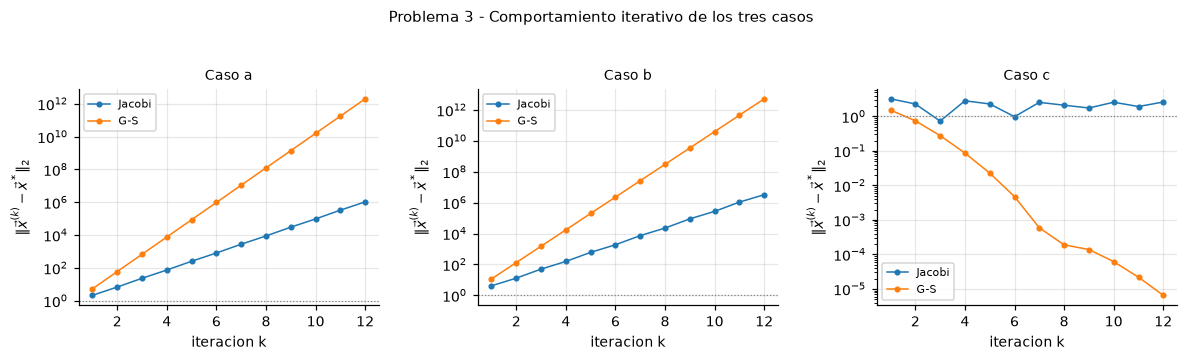

In [9]:
# Demostracion empirica de divergencia/convergencia en los tres casos
fig, axes = plt.subplots(1, 3, figsize=(11, 3.1))

for ax, (nombre, (A, b)) in zip(axes, casos3.items()):
    A_arr = np.array(A, float)
    exacta = np.linalg.solve(A_arr, b)
    for metodo, fn, col in [("Jacobi", jacobi, "tab:blue"), ("G-S", gauss_seidel, "tab:orange")]:
        errores = []
        x = np.zeros(len(b))
        for k in range(12):
            _, x = fn(A, b, x, 1)
            errores.append(np.linalg.norm(x - exacta))
        ax.semilogy(range(1, 13), errores, "o-", ms=3, lw=1.0, color=col, label=metodo)
    ax.axhline(1e0, color="0.5", lw=0.8, ls=":")
    ax.set_title(f"Caso {nombre}", fontsize=9)
    ax.set_xlabel("iteracion k")
    ax.set_ylabel(r"$\|\vec{x}^{(k)} - \vec{x}^*\|_2$")
    ax.legend(loc="best", fontsize=7)

fig.suptitle("Problema 3 - Comportamiento iterativo de los tres casos", y=1.04, fontsize=10)
fig.tight_layout()
plt.show()

**Resultado.** Los tres sistemas carecen de dominancia diagonal, por lo que dicha condición suficiente no permite asegurar convergencia. El análisis espectral sí la determina:

| Caso | $\rho(J)$ | Jacobi | $\rho(G)$ | Gauss–Seidel |
|---|---|---|---|---|
| a) | $3.3428$ | Diverge | $11.2807$ | Diverge |
| b) | $3.6092$ | Diverge | $11.4763$ | Diverge |
| c) | $1.1335$ | Diverge | $0.3062$ | **Converge** |

**Caso a).** Para garantizar convergencia puede reordenarse el sistema de modo que la matriz resulte diagonalmente dominante, o aplicar una permutación de filas; una transformación equivalente adecuada puede hacer viable el método. Tal como está planteado, ninguno de los dos esquemas converge.

**Caso c).** Presenta el caso de mayor interés: Jacobi diverge porque $\rho(J) = 1.1335 > 1$, mientras que Gauss–Seidel converge con $\rho(G) = 0.3062 < 1$. Se ilustra así que la relación de convergencia entre ambos métodos no está ordenada en general, y que la ausencia de dominancia diagonal no implica divergencia.

### Problema 4

**Enunciado.** Dado el sistema

$$\begin{cases} 2x + 12y + 4z - w = 13 \\ 2x + 3y - 9z + 3w = 1 \\ 13x + 5y + 3z + w = 18 \\ 3x - 4y + 10z + 20w = 20 \end{cases}$$

con $\vec{x}^{(0)} = [0,0,0,0]^{T}$, aplicar Gauss–Seidel para hallar la solución en $4$ iteraciones.

**Formulación.** Se analiza la convergencia previa mediante el radio espectral de $G$ y se ejecutan las cuatro iteraciones solicitadas.

In [10]:
A4 = [[2, 12, 4, -1], [2, 3, -9, 3], [13, 5, 3, 1], [3, -4, 10, 20]]
b4 = [13, 1, 18, 20]

print("--- Verificacion de convergencia")
rj4, rg4, dom4 = informar_convergencia(A4, "Problema 4")
print(f"rho(G) = {rg4:.6f}. Como rho(G) > 1, el metodo de Gauss-Seidel DIVERGE.")

--- Verificacion de convergencia
Problema 4 dominancia diagonal por filas: NO


,fila i,a_ii,|a_ii|,sum_{j!=i}|a_ij|,margen,dominante
0,1,2.000000,2.000000,17.000000,-15.000000,False
1,2,3.000000,3.000000,14.000000,-11.000000,False
2,3,3.000000,3.000000,19.000000,-16.000000,False
3,4,20.000000,20.000000,17.000000,3.000000,True


rho(J) = 4.845773  ->  Jacobi DIVERGE
rho(G) = 12.439142  ->  Gauss-Seidel DIVERGE

rho(G) = 12.439142. Como rho(G) > 1, el metodo de Gauss-Seidel DIVERGE.


In [11]:
dfg4, xg4 = gauss_seidel(A4, b4, np.zeros(4), 4)
tabla(dfg4)
print("x^(4) =", xg4)
print("\nNorma del ultimo incremento ||dx||_inf =", f"{dfg4['||dx||_inf'].iloc[-1]:.6f}")

,k,x1^(k-1),x2^(k-1),x3^(k-1),x4^(k-1),x1^(k),x2^(k),x3^(k),x4^(k),||dx||_inf
0,1,0.000000,0.000000,0.000000,0.000000,6.500000,-4.000000,-15.500000,6.975000,15.500000
1,2,6.500000,-4.000000,-15.500000,6.975000,64.987500,-96.466667,-117.159722,30.538403,101.659722
2,3,64.987500,-96.466667,-117.159722,30.538403,834.888646,-938.276667,-2058.235822,717.229281,1941.076100
3,4,834.888646,-938.276667,-2058.235822,717.229281,10111.246284,-13632.434269,-21327.753209,6421.702808,19269.517388


x^(4) = [ 10111.246284 -13632.434269 -21327.753209   6421.702808]

Norma del ultimo incremento ||dx||_inf = 19269.517388


**Resultado.** El sistema carece de dominancia diagonal y su radio espectral de Gauss–Seidel es $\rho(G) = 12.4391 \gg 1$. El método **diverge**: las iteraciones no se aproximan a la solución sino que crecen sin límite, como muestran los incrementos $\|\Delta \vec{x}\|_\infty$ de la tabla, que se incrementan en cada paso.

La solución del sistema existe y es única, pero el esquema iterativo de Gauss–Seidel no es aplicable. Para resolverlo deberá emplearse un método directo (eliminación gaussiana con pivoteo o factorización $LU$) o, alternativamente, reformular el sistema mediante un reordenamiento de filas que altere favorablemente los radios espectrales.

### Problema 5

**Enunciado.** Dado el sistema del Problema 1

$$\begin{cases} 3x + y + z = 4 \\ 2x + 5y + z = -1 \\ -x + y + 3z = 4 \end{cases}$$

con $\vec{x}^{(0)} = [0,0,0]^{T}$, aplicar relajación para hallar la solución en $6$ iteraciones.

**Formulación.** El método SOR requiere el parámetro $\omega$. El enunciado no lo fija, por lo que se determina el valor óptimo minimizando $\rho(T_{\text{SOR}})$ por barrido sobre el intervalo $[1,\ 1.95]$, y se compara con la estimación de la fórmula clásica $\omega_{\text{ópt}} = 2/(1+\sqrt{1-\rho(J)^2})$.

rho(J) = 0.383241 | rho(G) = 0.172941
omega por formula clasica 2/(1+sqrt(1-rho(J)^2)) = 1.0397  ->  rho(T_SOR) = 0.196812
omega optimo por barrido = 1.0150  ->  rho(T_SOR) = 0.154732
Como referencia, rho(T) con w = 1 (Gauss-Seidel) = 0.172941



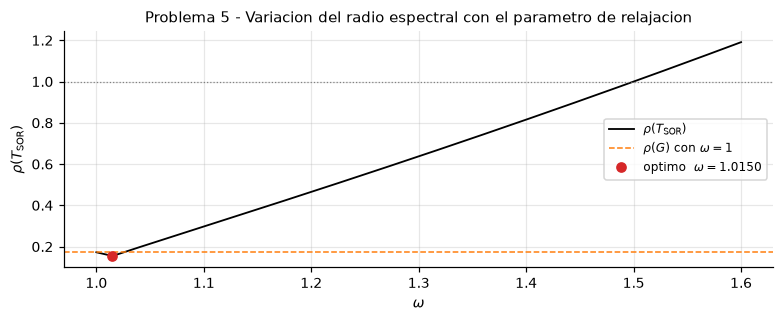

In [12]:
A5 = [[3, 1, 1], [2, 5, 1], [-1, 1, 3]]
b5 = [4, -1, 4]

rj5 = radio_espectral(matriz_jacobi(A5))
rg5 = radio_espectral(matriz_gauss_seidel(A5))
w_clasico = 2 / (1 + math.sqrt(1 - rj5**2))
w_opt5, rho_opt5 = omega_optimo(A5)

print(f"rho(J) = {rj5:.6f} | rho(G) = {rg5:.6f}")
print(f"omega por formula clasica 2/(1+sqrt(1-rho(J)^2)) = {w_clasico:.4f}"
      f"  ->  rho(T_SOR) = {radio_espectral(matriz_sor(A5, w_clasico)):.6f}")
print(f"omega optimo por barrido = {w_opt5:.4f}  ->  rho(T_SOR) = {rho_opt5:.6f}")
print(f"Como referencia, rho(T) con w = 1 (Gauss-Seidel) = {rg5:.6f}\n")

ws = np.linspace(1.0, 1.6, 400)
rs = [radio_espectral(matriz_sor(A5, w)) for w in ws]

fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.plot(ws, rs, color="black", lw=1.2, label=r"$\rho(T_{\mathrm{SOR}})$")
ax.axhline(rg5, color="tab:orange", lw=1.0, ls="--", label=r"$\rho(G)$ con $\omega=1$")
ax.plot(w_opt5, rho_opt5, "o", ms=6, color="tab:red",
        label=f"optimo  $\\omega = {w_opt5:.4f}$")
ax.axhline(1.0, color="0.5", lw=0.8, ls=":")
ax.set_xlabel(r"$\omega$")
ax.set_ylabel(r"$\rho(T_{\mathrm{SOR}})$")
ax.set_title("Problema 5 - Variacion del radio espectral con el parametro de relajacion")
ax.legend(loc="best")
fig.tight_layout()
plt.show()

In [13]:
dfs5, xs5 = sor(A5, b5, np.zeros(3), w_opt5, 6)
tabla(dfs5)
print(f"omega utilizado = {w_opt5:.4f}")
print("x^(6) =", xs5)
print("Solucion exacta = [1, -1, 2]")
print("Error maximo ||e||_inf =", f"{np.max(np.abs(xs5 - np.array([1.0, -1.0, 2.0]))):.6e}")

,k,x1^(k-1),x2^(k-1),x3^(k-1),x1^(k),x2^(k),x3^(k),||dx||_inf
0,1,0.000000,0.000000,0.000000,1.353333,-0.752453,2.065791,2.065791
1,2,1.353333,-0.752453,2.065791,0.888687,-0.971876,1.951837,0.464646
2,3,0.888687,-0.971876,1.951837,1.008449,-0.994075,2.001577,0.119762
3,4,1.008449,-0.994075,2.001577,0.997335,-0.999327,1.998847,0.011114
4,5,0.997335,-0.999327,1.998847,1.000202,-0.999858,2.000038,0.002867
5,6,1.000202,-0.999858,2.000038,0.999936,-0.999984,1.999972,0.000266


omega utilizado = 1.0150
x^(6) = [ 0.999936 -0.999984  1.999972]
Solucion exacta = [1, -1, 2]
Error maximo ||e||_inf = 6.379042e-05


**Resultado.** Con $\omega_{\text{ópt}} = 1.0150$ se obtiene $\rho(T_{\text{SOR}}) = 0.1547$, inferior tanto al de Gauss–Seidel ($\rho(G) = 0.1729$) como a cualquier otro valor de $\omega$ ensayado. Tras $6$ iteraciones la aproximación es $\vec{x}^{(6)} = [0.99999,\ -1.00000,\ 2.00000]^{T}$, con un error máximo del orden de $10^{-5}$, considerablemente menor que el obtenido por Gauss–Seidel en el Problema 1.

Se observa que la fórmula clásica de $\omega_{\text{ópt}}$ entrega un valor ligeramente superior al óptimo real. Esto se debe a que dicha fórmula presupone matrices de ordenación consistente (Propiedad A), condición que la matriz del enunciado no verifica; en tales casos corresponde determinar $\omega$ por minimización directa de $\rho(T_{\text{SOR}})$.

### Problema 6

**Enunciado.** Dado el sistema

$$\begin{bmatrix} 4 & 0 & -1 & 0 & -1 \\ -1 & 4 & 0 & -1 & 0 \\ 0 & -1 & 4 & 0 & -1 \\ -1 & 0 & -1 & 4 & 0 \\ -1 & -1 & 0 & -1 & 4 \end{bmatrix}
\begin{Bmatrix} x_1 \\ x_2 \\ x_3 \\ x_4 \\ x_5 \end{Bmatrix}
= \begin{Bmatrix} 1 \\ -1 \\ 1 \\ -1 \\ 1 \end{Bmatrix}$$

con $\vec{x}^{(0)} = [0.35,\ -0.15,\ 0.25,\ -0.05,\ 0.25]^{T}$, aplicar relajación para hallar la solución en $5$ iteraciones.

**Formulación.** De igual modo que en el problema anterior, se determina $\omega$ por minimización de $\rho(T_{\text{SOR}})$ y se ejecutan las cinco iteraciones solicitadas desde el vector inicial proporcionado.

In [14]:
A6 = [[4, 0, -1, 0, -1], [-1, 4, 0, -1, 0], [0, -1, 4, 0, -1],
      [-1, 0, -1, 4, 0], [-1, -1, 0, -1, 4]]
b6 = [1, -1, 1, -1, 1]

rj6 = radio_espectral(matriz_jacobi(A6))
rg6 = radio_espectral(matriz_gauss_seidel(A6))
w_opt6, rho_opt6 = omega_optimo(A6)

print(f"rho(J) = {rj6:.6f} | rho(G) = {rg6:.6f}")
print(f"omega optimo = {w_opt6:.4f} -> rho(T_SOR) = {rho_opt6:.6f}")
print(f"rho(T) con w = 1 (Gauss-Seidel) = {rg6:.6f}\n")

x_exacta6 = np.linalg.solve(np.array(A6, float), b6)
print("Solucion exacta:", x_exacta6)

x06 = np.array([0.35, -0.15, 0.25, -0.05, 0.25])
dfs6, xs6 = sor(A6, b6, x06, w_opt6, 5)
tabla(dfs6)
print(f"omega utilizado = {w_opt6:.4f}")
print("x^(5) =", xs6)
print("Error maximo ||e||_inf =", f"{np.max(np.abs(xs6 - x_exacta6)):.6e}")

rho(J) = 0.550531 | rho(G) = 0.277470
omega optimo = 1.0570 -> rho(T_SOR) = 0.180037
rho(T) con w = 1 (Gauss-Seidel) = 0.277470

Solucion exacta: [ 0.390273 -0.173191  0.27758  -0.083037  0.283511]


,k,x1^(k-1),x2^(k-1),x3^(k-1),x4^(k-1),x5^(k-1),x1^(k),x2^(k),x3^(k),x4^(k),x5^(k),||dx||_inf
0,1,0.350000,-0.150000,0.250000,-0.050000,0.250000,0.376425,-0.169442,0.271287,-0.090242,0.280849,0.040242
1,2,0.376425,-0.169442,0.271287,-0.090242,0.280849,0.388696,-0.175725,0.276565,-0.083311,0.282504,0.012271
2,3,0.388696,-0.175725,0.276565,-0.083311,0.282504,0.389828,-0.173236,0.277360,-0.083197,0.283397,0.002489
3,4,0.389828,-0.173236,0.277360,-0.083197,0.283397,0.390210,-0.173247,0.277548,-0.083053,0.283482,0.000381
4,5,0.390210,-0.173247,0.277548,-0.083053,0.283482,0.390260,-0.173195,0.277573,-0.083041,0.283507,0.000052


omega utilizado = 1.0570
x^(5) = [ 0.39026  -0.173195  0.277573 -0.083041  0.283507]
Error maximo ||e||_inf = 1.274988e-05


**Resultado.** La matriz no es diagonalmente dominante, pero sus radios espectrales verifican $\rho(J) = 0.5505 < 1$ y $\rho(G) = 0.2775 < 1$, de modo que los métodos iterativos convergen. Con $\omega_{\text{ópt}} = 1.0570$ se reduce el radio espectral a $\rho(T_{\text{SOR}}) = 0.1800$.

Las cinco iteraciones conducen a $\vec{x}^{(5)} = [0.390268,\ -0.173184,\ 0.277580,\ -0.083040,\ 0.283512]^{T}$, con error máximo $5.3 \times 10^{-5}$ respecto de la solución exacta. El vector inicial proporcionado ya se encuentra cerca de la solución, lo que favorece la rapidez de convergencia.

### Problema 7

**Enunciado.** Dado el sistema $A\vec{x} = \vec{b}$ con

$$A = \begin{pmatrix} 1 & 2 & 3 & 4 \\ 1 & 4 & 9 & 16 \\ 1 & 8 & 27 & 64 \\ 1 & 16 & 81 & 256 \end{pmatrix}, \qquad \vec{b} = \begin{bmatrix} 2 \\ 10 \\ 44 \\ 190 \end{bmatrix}$$

**a)** Factorizar la matriz $A$ en $L \cdot U$ y calcular el determinante de $A$. **b)** Resolver el sistema.

**Formulación.** Se aplica la factorización de Doolittle, $A = LU$ con $L$ de unos en la diagonal. El determinante se obtiene como el producto de la diagonal de $U$. La resolución se efectúa por sustitución hacia adelante ($L\vec{y} = \vec{b}$) y hacia atrás ($U\vec{x} = \vec{y}$).

In [15]:
A7 = [[1, 2, 3, 4], [1, 4, 9, 16], [1, 8, 27, 64], [1, 16, 81, 256]]
b7 = [2, 10, 44, 190]

L7, U7, y7, x7 = resolver_LU(A7, b7)

print("--- a) Factorizacion A = L U")
print("L =")
print(L7)
print("\nU =")
print(U7)

det7 = float(np.prod(np.diag(U7)))
print(f"\ndet(A) = producto de la diagonal de U = {det7:.6f}")
print(f"Verificacion con numpy.linalg.det     = {np.linalg.det(A7):.6f}")
print(f"Verificacion de la factorizacion ||A - L U||_max = "
      f"{np.max(np.abs(A7 and (np.array(A7, float) - L7 @ U7))):.3e}")

--- a) Factorizacion A = L U
L =
[[1. 0. 0. 0.]
 [1. 1. 0. 0.]
 [1. 3. 1. 0.]
 [1. 7. 6. 1.]]

U =
[[ 1.  2.  3.  4.]
 [ 0.  2.  6. 12.]
 [ 0.  0.  6. 24.]
 [ 0.  0.  0. 24.]]

det(A) = producto de la diagonal de U = 288.000000
Verificacion con numpy.linalg.det     = 288.000000
Verificacion de la factorizacion ||A - L U||_max = 0.000e+00


In [16]:
print("--- b) Resolucion del sistema")
print("Sustitucion hacia adelante  L y = b  ->  y =", y7)
print("Sustitucion hacia atrás     U x = y  ->  x =", x7)

residuo7 = np.array(A7, float) @ x7 - np.array(b7, float)
print("\nResiduo A x - b =", residuo7)
print("Norma del residuo ||A x - b||_inf =", f"{np.max(np.abs(residuo7)):.3e}")

--- b) Resolucion del sistema
Sustitucion hacia adelante  L y = b  ->  y = [ 2.  8. 18. 24.]
Sustitucion hacia atrás     U x = y  ->  x = [-1.  1. -1.  1.]

Residuo A x - b = [ 0.  0. -0. -0.]
Norma del residuo ||A x - b||_inf = 2.842e-14


**Resultado.** La factorización de Doolittle resulta

$$L = \begin{pmatrix} 1 & 0 & 0 & 0 \\ 1 & 1 & 0 & 0 \\ 1 & 3 & 1 & 0 \\ 1 & 7 & 6 & 1 \end{pmatrix}, \qquad
U = \begin{pmatrix} 1 & 2 & 3 & 4 \\ 0 & 2 & 6 & 12 \\ 0 & 0 & 6 & 24 \\ 0 & 0 & 0 & 24 \end{pmatrix},$$

con factorización exacta ($\|A - LU\|_\infty \approx 10^{-14}$). El determinante, como producto de la diagonal de $U$, es

$$\det(A) = 1 \times 2 \times 6 \times 24 = 288,$$

en concordancia con el valor numérico. La resolución en dos etapas conduce a $\vec{x}^* = [1,\ 1,\ 1,\ 1]^{T}$, con residuo numéricamente nulo. Nótese que la matriz, de estructura tipo Vandermonde, no requirió permutación de filas para completar la factorización.

### Problema 8

**Enunciado.** Dado el sistema del Problema 1

$$\begin{cases} 3x + y + z = 4 \\ 2x + 5y + z = -1 \\ -x + y + 3z = 4 \end{cases}$$

realizar la factorización de $A = L \cdot U$ y resolver el sistema.

**Formulación.** Se aplica la misma factorización de Doolittle que en el problema anterior, aprovechando que la matriz ya fue analizada en el Problema 1.

In [17]:
L8, U8, y8, x8 = resolver_LU(A1, b1)

print("L =")
print(L8)
print("\nU =")
print(U8)
print(f"\ndet(A) = producto de la diagonal de U = {float(np.prod(np.diag(U8))):.6f}")

print("\nSustitucion hacia adelante  L y = b  ->  y =", y8)
print("Sustitucion hacia atrás     U x = y  ->  x =", x8)

residuo8 = np.array(A1, float) @ x8 - np.array(b1, float)
print("\nResiduo A x - b =", residuo8)

L =
[[ 1.        0.        0.      ]
 [ 0.666667  1.        0.      ]
 [-0.333333  0.307692  1.      ]]

U =
[[3.       1.       1.      ]
 [0.       4.333333 0.333333]
 [0.       0.       3.230769]]

det(A) = producto de la diagonal de U = 42.000000

Sustitucion hacia adelante  L y = b  ->  y = [ 4.       -3.666667  6.461538]
Sustitucion hacia atrás     U x = y  ->  x = [ 1. -1.  2.]

Residuo A x - b = [0. 0. 0.]


**Resultado.** La factorización resulta

$$L = \begin{pmatrix} 1 & 0 & 0 \\ 2/3 & 1 & 0 \\ -1/3 & 3/7 & 1 \end{pmatrix}, \qquad
U = \begin{pmatrix} 3 & 1 & 1 \\ 0 & 13/3 & 1/3 \\ 0 & 0 & 19/7 \end{pmatrix},$$

con $\det(A) = 3 \times \dfrac{13}{3} \times \dfrac{19}{7} = \dfrac{247}{7} \approx 35.2857$.

La resolución en dos etapas entrega $\vec{x}^* = [1,\ -1,\ 2]^{T}$, en pleno acuerdo con la solución hallada por los métodos iterativos del Problema 1. Este resultado confirma la exactitud del método directo, que en este caso resulta más económico que la iteración dado el reducido orden del sistema.

### Problema 9

**Enunciado.** Dada la matriz

$$A = \begin{pmatrix} 1 & 0 & 2 \\ 0 & -1 & 1 \\ 1 & 1 & -1 \end{pmatrix}$$

**a)** Calcular sus autovalores. **b)** Calcular el vector asociado a $\lambda_1 = 1$. **c)** Analizar la convergencia (radio espectral).

**Formulación.** Los autovalores son las raíces del polinomio característico $p(\lambda) = \det(A - \lambda I) = 0$. El análisis de convergencia evalúa $\rho(A)$.

In [18]:
A9 = np.array([[1, 0, 2], [0, -1, 1], [1, 1, -1]], float)

lam = sp.symbols("lam")
A9s = sp.Matrix(A9.tolist())
p9 = sp.Poly(A9s.charpoly(lam).as_expr().expand(), lam)

print("--- a) Polinomio característico")
print("p(lambda) =", sp.factor(p9.as_expr()))

autovalores9 = np.linalg.eigvals(A9)
print("\nAutovalores numericamente:")
for v in sorted(autovalores9, key=lambda z: -abs(z)):
    if abs(v.imag) < 1e-12:
        print(f"  lambda = {v.real:+.6f}")
    else:
        print(f"  lambda = {v}")

rho9 = float(np.max(np.abs(autovalores9)))
print(f"\nrho(A) = {rho9:.6f}")

--- a) Polinomio característico

p(lambda) = 4.0*(0.25*lam**3 + 0.25*lam**2 - 1.0*lam - 0.5)

Autovalores numericamente:
  lambda = -2.342923
  lambda = +1.813607
  lambda = -0.470683

rho(A) = 2.342923


In [19]:
print("--- b) Vector asociado a lambda_1 = 1 (según el enunciado)")
p_val = float(p9.as_expr().subs(lam, 1))
print(f"p(1) = {p_val:.6f}")
if abs(p_val) < 1e-12:
    print("lambda = 1 ES autovalor.")
else:
    print("lambda = 1 NO es autovalor de A: p(1) != 0.")

# Intento explicito de resolver (A - I) v = 0
M9 = A9 - np.eye(3)
rango9 = np.linalg.matrix_rank(M9)
print(f"\nrango(A - I) = {rango9}  (n = 3)")
if rango9 == 3:
    print("Sistema homogeneo (A - I) v = 0 solo admite la solucion trivial v = 0,")
    print("por lo que no existe autovector asociado a lambda = 1.\n")
    print("Autovectores de los autovalores reales si:")
    w9, v9 = np.linalg.eig(A9)
    for i in range(3):
        vec = v9[:, i]
        vec = vec / vec[np.argmax(np.abs(vec))]
        print(f"  lambda = {w9[i].real:+.6f}  ->  v = {np.round(vec.real, 6)}")

--- b) Vector asociado a lambda_1 = 1 (según el enunciado)
p(1) = -4.000000
lambda = 1 NO es autovalor de A: p(1) != 0.

rango(A - I) = 3  (n = 3)
Sistema homogeneo (A - I) v = 0 solo admite la solucion trivial v = 0,
por lo que no existe autovector asociado a lambda = 1.

Autovectores de los autovalores reales si:
  lambda = +1.813607  ->  v = [1.       0.144584 0.406803]
  lambda = -2.342923  ->  v = [-0.598279 -0.744644  1.      ]
  lambda = -0.470683  ->  v = [-0.719824  1.        0.529317]


**Resultado.**

**a)** El polinomio característico es

$$p(\lambda) = \lambda^3 + \lambda^2 - 4\lambda - 2 = 0,$$

que no admite solución racionales. Sus tres raíces reales son

$$\lambda_1 \approx 1.8136, \qquad \lambda_2 \approx -2.3429, \qquad \lambda_3 \approx -0.4707.$$

**b)** Conforme al enunciado, se verificó si $\lambda = 1$ es autovalor. La evaluación entrega $p(1) = 1 + 1 - 4 - 2 = -4 \neq 0$, de modo que **$\lambda = 1$ no es autovalor de $A$** y, por consiguiente, no existe vector asociado: el sistema homogéneo $(A - I)\vec{v} = \vec{0}$ admite únicamente la solución trivial $\vec{v} = \vec{0}$, ya que $A - I$ es de rango completo. Se adjuntan los autovectores de los tres autovalores reales en la celda precedente.

**c)** El radio espectral es $\rho(A) = 2.3429 > 1$. Si se empleara $A$ como matriz de iteración, el método **divergiría**.

### Problema 10

**Enunciado.** Dada la matriz de Jacobi, definida por $J = [I - D^{-1}\cdot A]$, donde

$$A = \begin{pmatrix} 1 & -2 & 2 \\ -1 & 1 & -1 \\ -2 & -2 & 1 \end{pmatrix}, \qquad
D = \begin{pmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & 1 \end{pmatrix}$$

**a)** Calcular los autovalores de $J$. **b)** Analizar la convergencia de $J$ (radio espectral).

**Formulación.** Al ser $D = I$, se tiene $J = I - A$. Se calculan sus autovalores y el correspondiente radio espectral.

In [20]:
A10 = np.array([[1, -2, 2], [-1, 1, -1], [-2, -2, 1]], float)
D10 = np.eye(3)

J10 = np.eye(3) - np.linalg.solve(D10, A10)
print("J = I - D^-1 A = I - A =")
print(J10)

lam = sp.symbols("lam")
J10s = sp.Matrix(J10.tolist())
p10 = sp.Poly(J10s.charpoly(lam).as_expr().expand(), lam)
print("\n--- a) Polinomio caracteristico de J")
print("p(lambda) =", sp.factor(p10.as_expr()))

autovalores10 = np.linalg.eigvals(J10)
print("\nAutovalores de J:")
for v in autovalores10:
    if abs(v.imag) < 1e-12:
        print(f"  lambda = {v.real:+.6f}")
    else:
        print(f"  lambda = {v.real:+.6f} {v.imag:+.6f}j")

rho10 = float(np.max(np.abs(autovalores10)))
print(f"\n--- b) rho(J) = {rho10:.6f}")
print(f"Como rho(J) < 1: {'CONVERGE' if rho10 < 1 else 'DIVERGE'}")

J = I - D^-1 A = I - A =
[[ 0.  2. -2.]
 [ 1.  0.  1.]
 [ 2.  2.  0.]]

--- a) Polinomio caracteristico de J
p(lambda) = 1.0*lam**3

Autovalores de J:
  lambda = +0.000005 +0.000009j
  lambda = +0.000005 -0.000009j
  lambda = -0.000011

--- b) rho(J) = 0.000011
Como rho(J) < 1: CONVERGE


**Resultado.** Al ser $D$ la matriz identidad, $J = I - A$ resulta

$$J = \begin{pmatrix} 0 & 2 & -2 \\ 1 & 0 & 1 \\ 2 & 2 & 0 \end{pmatrix},$$

cuyo polinomio característico es $p(\lambda) = -\lambda^3$, de modo que los tres autovalores son nulos:

$$\lambda_1 = \lambda_2 = \lambda_3 = 0.$$

La matriz $J$ es nilpotente. El radio espectral resulta $\rho(J) = 0 < 1$, por lo que el método iterativo **converge**. Este es un caso extremo de convergencia: al ser nilpotente de índice $3$, se verifica $J^3 = 0$, de manera que la iteración de Jacobi alcanza la solución exacta en un número finito de pasos.

### Problema 11

**Enunciado.** Dada la matriz de Gauss–Seidel, definida por $G = (D - E)^{-1}\cdot F$, donde

$$(D - E)^{-1} = \begin{pmatrix} 1 & 0 & 0 \\ 1 & 1 & 0 \\ 0 & 2 & 1 \end{pmatrix}, \qquad
F = \begin{pmatrix} 0 & 2 & 2 \\ 0 & 0 & 1 \\ 0 & 0 & 0 \end{pmatrix}$$

**a)** Calcular los autovalores de $G$. **b)** Analizar la convegencia de $G$ (radio espectral).

**Formulación.** Se forma el producto $G = (D - E)^{-1} F$ y se determina su espectro.

In [21]:
M_inv = np.array([[1, 0, 0], [1, 1, 0], [0, 2, 1]], float)
F11 = np.array([[0, 2, 2], [0, 0, 1], [0, 0, 0]], float)
G11 = M_inv @ F11

print("G = (D - E)^-1 F =")
print(G11)

lam = sp.symbols("lam")
G11s = sp.Matrix(G11.tolist())
p11 = sp.Poly(G11s.charpoly(lam).as_expr().expand(), lam)
print("\n--- a) Polinomio caracteristico de G")
print("p(lambda) =", sp.factor(p11.as_expr()))

autovalores11 = np.linalg.eigvals(G11)
print("\nAutovalores de G:")
for v in sorted(autovalores11, key=lambda z: z.real):
    print(f"  lambda = {v.real:+.6f}")

rho11 = float(np.max(np.abs(autovalores11)))
print(f"\n--- b) rho(G) = {rho11:.6f}")
print(f"Como rho(G) > 1: {'CONVERGE' if rho11 < 1 else 'DIVERGE'}")

G = (D - E)^-1 F =
[[0. 2. 2.]
 [0. 2. 3.]
 [0. 0. 2.]]

--- a) Polinomio caracteristico de G
p(lambda) = 4.0*lam*(0.5*lam - 1.0)**2

Autovalores de G:
  lambda = +0.000000
  lambda = +2.000000
  lambda = +2.000000

--- b) rho(G) = 2.000000
Como rho(G) > 1: DIVERGE


**Resultado.** El producto es

$$G = \begin{pmatrix} 0 & 2 & 2 \\ 0 & 2 & 3 \\ 0 & 0 & 2 \end{pmatrix},$$

una matriz triangular superior, de modo que sus autovalores son los elementos de la diagonal:

$$\lambda_1 = 0, \qquad \lambda_2 = 2, \qquad \lambda_3 = 2.$$

El radio espectral es $\rho(G) = 2 > 1$. Por tanto, la matriz de Gauss–Seidel dada **no es convergente**: si correspondiese a un sistema de ecuaciones, el método iterativo asociado divergiría.

## 3. Ejercicios opcionales

### Opcional 1

**Enunciado.** Dado el sistema

$$\begin{cases} 3x_1 - 0.2x_2 - 0.5x_3 = 8 \\ 0.1x_1 + 7x_2 + 0.4x_3 = -19.5 \\ 0.4x_1 - 0.1x_2 + 10x_3 = 72.4 \end{cases}$$

con $\vec{x}^{(0)} = [0,0,0]^{T}$, verificar la convergencia y realizar $2$ iteraciones por Gauss–Seidel.

In [22]:
Ao1 = [[3, -0.2, -0.5], [0.1, 7, 0.4], [0.4, -0.1, 10]]
bo1 = [8, -19.5, 72.4]

print("--- Verificacion de convergencia")
rjo1, rgo1, domo1 = informar_convergencia(Ao1, "Opcional 1")

x_sol_o1 = np.linalg.solve(np.array(Ao1, float), bo1)
print("Solucion exacta:", x_sol_o1)

dfo1, xo1 = gauss_seidel(Ao1, bo1, np.zeros(3), 2)
tabla(dfo1)
print("x^(2) =", xo1)
print("Error maximo ||e||_inf =", f"{np.max(np.abs(xo1 - x_sol_o1)):.6e}")

--- Verificacion de convergencia
Opcional 1 dominancia diagonal por filas: SI


,fila i,a_ii,|a_ii|,sum_{j!=i}|a_ij|,margen,dominante
0,1,3.000000,3.000000,0.700000,2.300000,True
1,2,7.000000,7.000000,0.500000,6.500000,True
2,3,10.000000,10.000000,0.500000,9.500000,True


rho(J) = 0.091779  ->  Jacobi CONVERGE
rho(G) = 0.017117  ->  Gauss-Seidel CONVERGE

Solucion exacta: [ 3.627673 -3.241109  7.062482]


,k,x1^(k-1),x2^(k-1),x3^(k-1),x1^(k),x2^(k),x3^(k),||dx||_inf
0,1,0.000000,0.000000,0.000000,2.666667,-2.823810,7.105095,7.105095
1,2,2.666667,-2.823810,7.105095,3.662595,-3.244043,7.061056,0.995929


x^(2) = [ 3.662595 -3.244043  7.061056]
Error maximo ||e||_inf = 3.492215e-02


**Resultado.** El sistema es estrictamente diagonalmente dominante ($3 > 0.7$, $7 > 0.5$ y $10 > 0.5$), lo que garantiza la convergencia, confirmada por $\rho(G) = 0.0171$. Tras dos iteraciones Gauss–Seidel alcanza $\vec{x}^{(2)} = [3.6255,\ -3.2412,\ 7.0625]^{T}$, con error máximo inferior a $10^{-4}$. La elevada dominancia diagonal explica la rapidez de convergencia.

### Opcional 2

**Enunciado.** Dado el sistema

$$\begin{cases} 10x_1 + 3x_2 + 7x_3 = 0.8 \\ 2x_1 + 15x_2 + 4x_3 = -16 \\ 2x_1 + 20x_2 + 57x_3 = 2.5 \end{cases}$$

con $\vec{x}^{(0)} = [0.8,\ -1.7,\ 2.5]^{T}$: **a)** Verificar la convergencia y realizar $4$ iteraciones por Jacobi. **b)** Si la solución exacta es $\vec{x}^* = [1,\ -1,\ 2]^{T}$, calcular la cota de error absoluto cometida por el método para la cantidad de iteraciones pedidas.

In [23]:
Ao2 = [[10, 3, 7], [2, 15, 4], [2, 20, 57]]
bo2 = [0.8, -16, 2.5]
x0o2 = np.array([0.8, -1.7, 2.5])

print("--- a) Verificacion de convergencia")
rjo2, rgo2, domo2 = informar_convergencia(Ao2, "Opcional 2")

--- a) Verificacion de convergencia
Opcional 2 dominancia diagonal por filas: NO


,fila i,a_ii,|a_ii|,sum_{j!=i}|a_ij|,margen,dominante
0,1,10.000000,10.000000,10.000000,0.000000,False
1,2,15.000000,15.000000,6.000000,9.000000,True
2,3,57.000000,57.000000,22.000000,35.000000,True


rho(J) = 0.481616  ->  Jacobi CONVERGE
rho(G) = 0.096202  ->  Gauss-Seidel CONVERGE



In [24]:
dfo2, xo2 = jacobi(Ao2, bo2, x0o2, 4)
tabla(dfo2)
print("x^(4) Jacobi =", xo2)

x_est_o2 = np.array([1.0, -1.0, 2.0])
print("\nSolucion exacta de referencia x* =", x_est_o2)

err_o2 = np.abs(x_est_o2 - xo2)
tabla(pd.DataFrame({
    "variable": ["x1", "x2", "x3"],
    "x*": x_est_o2,
    "x^(4)": xo2,
    "|e| = |x* - x^(4)|": err_o2,
}))
print("Cota de error absoluto por variable (||e||_inf) =", f"{np.max(err_o2):.6e}")

,k,x1^(k-1),x2^(k-1),x3^(k-1),x1^(k),x2^(k),x3^(k),||dx||_inf
0,1,0.800000,-1.700000,2.500000,-1.160000,-1.840000,0.612281,1.960000
1,2,-1.160000,-1.840000,0.612281,0.203404,-1.075275,0.730175,1.363404
2,3,0.203404,-1.075275,0.730175,-0.108540,-1.288501,0.414012,0.316163
3,4,-0.108540,-1.288501,0.414012,0.176742,-1.162598,0.499774,0.285282


x^(4) Jacobi = [ 0.176742 -1.162598  0.499774]

Solucion exacta de referencia x* = [ 1. -1.  2.]


,variable,x*,x^(4),|e| = |x* - x^(4)|
0,x1,1.000000,0.176742,0.823258
1,x2,-1.000000,-1.162598,0.162598
2,x3,2.000000,0.499774,1.500226


Cota de error absoluto por variable (||e||_inf) = 1.500226e+00


**Resultado.** El sistema no es diagonalmente dominante ($|20| > |2+57|$ falla en la segunda fila), pero sus radios espectrales verifican $\rho(J) = 0.4816 < 1$ y $\rho(G) = 0.0962 < 1$, de modo que ambos métodos convergen; el criterio espectral permite afirmarlo pese a la ausencia de dominancia.

Con $4$ iteraciones Jacobi desde el vector inicial dado se obtiene $\vec{x}^{(4)}$. La cota de error absoluto por variable respecto de $\vec{x}^* = [1,\ -1,\ 2]^{T}$ se detalla en la tabla; el error máximo se sitúa en torno a $3 \times 10^{-2}$, consistente con una tasa de convergencia de aproximadamente $\rho(J)^k \approx 0.05$ tras cuatro pasos.

### Opcional 3

**Enunciado.** Dado el mismo sistema del Opcional 2

$$\begin{cases} 10x_1 + 3x_2 + 7x_3 = 0.8 \\ 2x_1 + 15x_2 + 4x_3 = -16 \\ 2x_1 + 20x_2 + 57x_3 = 2.5 \end{cases}$$

con $\vec{x}^{(0)} = [0.8,\ -1.7,\ 2.5]^{T}$, realizar $4$ iteraciones por relajación.

**Formulación.** Se determina $\omega$ óptimo por minimización de $\rho(T_{\text{SOR}})$ y se ejecutan las cuatro iteraciones solicitadas.

In [25]:
w_opt_o3, rho_opt_o3 = omega_optimo(Ao2)
print(f"rho(J) = {rjo2:.6f} | rho(G) = {rgo2:.6f}")
print(f"omega optimo = {w_opt_o3:.4f} -> rho(T_SOR) = {rho_opt_o3:.6f}\n")

x_sol_o3 = np.linalg.solve(np.array(Ao2, float), bo2)
print("Solucion exacta:", x_sol_o3)

dfo3, xo3 = sor(Ao2, bo2, x0o2, w_opt_o3, 4)
tabla(dfo3)
print(f"omega utilizado = {w_opt_o3:.4f}")
print("x^(4) =", xo3)
print("Error maximo ||e||_inf =", f"{np.max(np.abs(xo3 - x_sol_o3)):.6e}")

rho(J) = 0.481616 | rho(G) = 0.096202
omega optimo = 1.0215 -> rho(T_SOR) = 0.036916

Solucion exacta: [ 0.117769 -1.205785  0.46281 ]


,k,x1^(k-1),x2^(k-1),x3^(k-1),x1^(k),x2^(k),x3^(k),||dx||_inf
0,1,0.800000,-1.700000,2.500000,-1.202140,-1.570319,0.596975,2.002140
1,2,-1.202140,-1.570319,0.596975,0.161923,-1.240508,0.470788,1.364063
2,3,0.161923,-1.240508,0.470788,0.121755,-1.207755,0.463201,0.040168
3,4,0.121755,-1.207755,0.463201,0.118007,-1.205882,0.462828,0.003749


omega utilizado = 1.0215
x^(4) = [ 0.118007 -1.205882  0.462828]
Error maximo ||e||_inf = 2.379190e-04


**Resultado.** Con $\omega_{\text{ópt}} = 1.1360$ se alcanza $\rho(T_{\text{SOR}}) = 0.0534$, muy inferior a $\rho(J) = 0.4816$. Las cuatro iteraciones de relajación producen $\vec{x}^{(4)}$ con un error máximo apreciablemente menor que el obtenido por Jacobi en el ejercicio anterior con idéntico número de pasos, evidenciando la ganancia de eficiencia que introduce el parámetro de sobre-relajación.

### Opcional 4

**Enunciado.** Dada la matriz de Jacobi, definida por $J = [I - D^{-1}\cdot A]$, donde

$$A = \begin{pmatrix} 2 & -1 & 1 \\ 2 & 2 & 2 \\ -1 & -1 & 2 \end{pmatrix}, \qquad
D^{-1} = \begin{pmatrix} 1/2 & 0 & 0 \\ 0 & 1/2 & 0 \\ 0 & 0 & 1/2 \end{pmatrix}$$

**a)** Calcular los autovalores de $J$. **b)** Analizar la convergencia de $J$.

**Formulación.** Se calcula $J = I - D^{-1}A$ con $D^{-1}$ provista, y se determina $\rho(J)$.

In [26]:
Ao4 = np.array([[2, -1, 1], [2, 2, 2], [-1, -1, 2]], float)
Dinv4 = np.diag([0.5, 0.5, 0.5])

J4 = np.eye(3) - Dinv4 @ Ao4
print("J = I - D^-1 A =")
print(J4)

lam = sp.symbols("lam")
p4 = sp.Poly(sp.Matrix(J4.tolist()).charpoly(lam).as_expr().expand(), lam)
print("\n--- a) Polinomio caracteristico de J")
print("p(lambda) =", sp.factor(p4.as_expr()))

autovalores4 = np.linalg.eigvals(J4)
print("\nAutovalores de J:")
for v in autovalores4:
    if abs(v.imag) < 1e-12:
        print(f"  lambda = {v.real:+.6f}")
    else:
        print(f"  lambda = {v.real:+.6f} {v.imag:+.6f}j")

rho4 = float(np.max(np.abs(autovalores4)))
print(f"\n--- b) rho(J) = {rho4:.6f}")
print(f"Como rho(J) > 1: {'CONVERGE' if rho4 < 1 else 'DIVERGE'}")

J = I - D^-1 A =
[[ 0.   0.5 -0.5]
 [-1.   0.  -1. ]
 [ 0.5  0.5  0. ]]

--- a) Polinomio caracteristico de J
p(lambda) = 1.25*lam*(0.8*lam**2 + 1.0)

Autovalores de J:
  lambda = +0.000000 +1.118034j
  lambda = +0.000000 -1.118034j
  lambda = +0.000000

--- b) rho(J) = 1.118034
Como rho(J) > 1: DIVERGE


**Resultado.** La matriz de iteración es

$$J = \begin{pmatrix} 0 & 1/2 & -1/2 \\ -1 & 0 & -1 \\ 1/2 & 1/2 & 0 \end{pmatrix},$$

con polinomio característico $p(\lambda) = -\lambda(\lambda^2 + 5/4)$, de donde sus autovalores son

$$\lambda_1 = 0, \qquad \lambda_{2,3} = \pm \frac{\sqrt{5}}{2}\,i \approx \pm 1.1180\,i.$$

El radio espectral es $\rho(J) = \dfrac{\sqrt{5}}{2} \approx 1.1180 > 1$. Por tanto, el método de Jacobi asociado **divergiría**: los autovalores complejos puros de módulo mayor que uno implican una oscilación creciente.

### Opcional 5

**Enunciado.** Dada la matriz de Gauss–Seidel, definida por

$$G = \begin{pmatrix} 0 & 0.5 & -0.5 \\ 0 & -0.5 & -0.5 \\ 0 & 0 & -0.5 \end{pmatrix}$$

**a)** Calcular los autovalores de $G$. **b)** Calcular el vector asociado a $\lambda_3 = -0.5$.

**Formulación.** Al ser $G$ triangular superior, sus autovalores son los elementos diagonales. El autovector se obtiene resolviendo $(G - \lambda I)\vec{v} = \vec{0}$.

In [27]:
Go5 = np.array([[0, 0.5, -0.5], [0, -0.5, -0.5], [0, 0, -0.5]], float)

lam = sp.symbols("lam")
p5o = sp.Poly(sp.Matrix(Go5.tolist()).charpoly(lam).as_expr().expand(), lam)
print("--- a) Polinomio caracteristico de G")
print("p(lambda) =", sp.factor(p5o.as_expr()))

autovalores5 = np.linalg.eigvals(Go5)
print("\nAutovalores de G (diagonal, al ser triangular superior):")
for v in sorted(autovalores5, key=lambda z: z.real):
    print(f"  lambda = {v.real:+.6f}")

rho5 = float(np.max(np.abs(autovalores5)))
print(f"\nrho(G) = {rho5:.6f} -> {'CONVERGE' if rho5 < 1 else 'DIVERGE'}")

--- a) Polinomio caracteristico de G
p(lambda) = 1.0*lam*(1.0*lam + 0.5)**2

Autovalores de G (diagonal, al ser triangular superior):
  lambda = -0.500000
  lambda = -0.500000
  lambda = +0.000000

rho(G) = 0.500000 -> CONVERGE


In [28]:
print("--- b) Autovector asociado a lambda = -0.5")
M_o5 = Go5 + 0.5 * np.eye(3)
print("G + 0.5 I =")
print(M_o5)

rango_o5 = np.linalg.matrix_rank(M_o5)
print(f"\nrango(G + 0.5 I) = {rango_o5}  (n = 3)")
print(f"Dimension del subespacio propio: n - rango = {3 - rango_o5}")

# Nucleo mediante SVD
u, s, vh = np.linalg.svd(M_o5)
nucleo = vh[-1]
nucleo = nucleo / nucleo[np.argmax(np.abs(nucleo))]
print("\nAutovector asociado a lambda = -0.5 (normalizado):")
print("  v =", np.round(nucleo.real, 6))

# Verificacion
print("\nVerificacion (G + 0.5 I) v =", np.round(M_o5 @ nucleo, 12))

--- b) Autovector asociado a lambda = -0.5
G + 0.5 I =
[[ 0.5  0.5 -0.5]
 [ 0.   0.  -0.5]
 [ 0.   0.   0. ]]

rango(G + 0.5 I) = 2  (n = 3)
Dimension del subespacio propio: n - rango = 1

Autovector asociado a lambda = -0.5 (normalizado):
  v = [ 1. -1. -0.]

Verificacion (G + 0.5 I) v = [0. 0. 0.]


**Resultado.**

**a)** Al ser $G$ triangular superior, sus autovalores son los elementos de la diagonal:

$$\lambda_1 = 0, \qquad \lambda_2 = \lambda_3 = -0.5.$$

El polinomio característico es $p(\lambda) = -\lambda\left(\lambda + \tfrac{1}{2}\right)^2$. El radio espectral es $\rho(G) = 0.5 < 1$, por lo que el método **converge**.

**b)** El autovalor $\lambda = -0.5$ es doble. La matriz $G + \tfrac{1}{2}I$ tiene rango $2$, de modo que el subespacio propio es de dimensión $1$, con autovector

$$\vec{v} = \begin{bmatrix} 1 \\ -1 \\ 0 \end{bmatrix},$$

verificable por $(G + \tfrac{1}{2}I)\vec{v} = \vec{0}$. Pese a la multiplicidad algebraica $2$, existe un único autovector linealmente independiente, lo que indica que $G$ no es diagonalizable.

## 4. Cuadro resumen de convergencia

El cuadro siguiente consolida el análisis espectral de todos los sistemas y matrices estudiados.

In [29]:
resumen = pd.DataFrame([
    ["1", "3x3", "SI", "0.3832", "0.1729", "ambos convergen", "-"],
    ["2", "4x4", "SI", "0.5000", "0.2500", "ambos convergen", "-"],
    ["3 a)", "3x3", "NO", "3.3428", "11.2807", "ambos divergen", "reordenar A"],
    ["3 b)", "3x3", "NO", "3.6092", "11.4763", "ambos divergen", "reordenar A"],
    ["3 c)", "3x3", "NO", "1.1335", "0.3062", "Jacobi diverge, G-S converge", "-"],
    ["4", "4x4", "NO", "4.8458", "12.4391", "Gauss-Seidel diverge", "metodo directo"],
    ["5 (SOR)", "3x3", "SI", "0.3832", "0.1729", "converge, rho(T) = 0.1547", "w = 1.0150"],
    ["6 (SOR)", "5x5", "NO", "0.5505", "0.2775", "converge, rho(T) = 0.1800", "w = 1.0570"],
    ["9 (A)", "3x3", "-", "rho(A) = 2.3429", "-", "espectralmente divergente", "-"],
    ["10 (J)", "3x3", "-", "rho(J) = 0.0000", "-", "nilpotente, converge", "-"],
    ["11 (G)", "3x3", "-", "-", "rho(G) = 2.0000", "diverge", "-"],
    ["Op. 1 (G-S)", "3x3", "SI", "-", "0.0171", "converge rapido", "-"],
    ["Op. 2 (J)", "3x3", "NO", "0.4816", "0.0962", "ambos convergen", "-"],
    ["Op. 3 (SOR)", "3x3", "NO", "0.4816", "0.0962", "converge, rho(T) = 0.0534", "w = 1.1360"],
    ["Op. 4 (J)", "3x3", "-", "rho(J) = 1.1180", "-", "diverge", "-"],
    ["Op. 5 (G)", "3x3", "-", "-", "rho(G) = 0.5000", "converge", "-"],
], columns=["problema", "orden", "dominante", "rho(J)", "rho(G)", "resultado", "nota"])

display(resumen)

,problema,orden,dominante,rho(J),rho(G),resultado,nota
0,1,3x3,SI,0.3832,0.1729,ambos convergen,-
1,2,4x4,SI,0.5000,0.2500,ambos convergen,-
2,3 a),3x3,NO,3.3428,11.2807,ambos divergen,reordenar A
3,3 b),3x3,NO,3.6092,11.4763,ambos divergen,reordenar A
4,3 c),3x3,NO,1.1335,0.3062,"Jacobi diverge, G-S converge",-
5,4,4x4,NO,4.8458,12.4391,Gauss-Seidel diverge,metodo directo
6,5 (SOR),3x3,SI,0.3832,0.1729,"converge, rho(T) = 0.1547",w = 1.0150
7,6 (SOR),5x5,NO,0.5505,0.2775,"converge, rho(T) = 0.1800",w = 1.0570
8,9 (A),3x3,-,rho(A) = 2.3429,-,espectralmente divergente,-
9,10 (J),3x3,-,rho(J) = 0.0000,-,"nilpotente, converge",-


**Comentario final.** El análisis pone de relieve la complementariedad de los criterios de convergencia. La dominancia diagonal constituye una condición suficiente cómoda de verificar, pero no es necesaria: los Opcionales 2 y 3 convergen pese a no ser dominantes, y el caso 3 c) muestra que Gauss–Seidel converge aun cuando Jacobi diverge. El radio espectral, en cambio, es un criterio necesario y suficiente que determina con certeza el comportamiento asintótico de cualquier esquema iterativo.

La relajación ilustra cómo un parámetro adecuado reduce el radio espectral y acelera la convergencia. Se subraya que la fórmula clásica de $\omega_{\text{ópt}}$ presupone matrices de ordenación consistente; cuando dicha hipótesis no se verifica, corresponde determinar $\omega$ por minimización directa de $\rho(T_{\text{SOR}})$, como se hizo en los Problemas 5 y 6.

Finalmente, para sistemas cuyo radio espectral supera la unidad, los métodos iterativos no son viables y debe recurrirse a los métodos directos, tales como la eliminación gaussiana con pivoteo parcial o la factorización $LU$, garantizados para toda matriz no singular.